<a href="https://colab.research.google.com/github/PanconquesoHH/Laboratorios-ia/blob/main/Aprendizaje_por_refuerzo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Este cuadernillo presenta una simulación del juego de los Cofres del Tesoro, donde un agente de aprendizaje por refuerzo debe identificar la opción más rentable dentro de un entorno de 10 cofres con recompensas aleatorias distribuidas normalmente. El proyecto inicia con una representación gráfica del entorno que muestra los 10 cofres y sus respectivas recompensas medias reales ($\mu$).A lo largo de 1000 iteraciones, se analizan y comparan tres estrategias fundamentales: Greedy ($\epsilon=0.0$), $\epsilon$-Greedy configurado con una alta tasa de exploración ($\epsilon=0.8$, correspondiente a un 80% de exploración y 20% de explotación) y Upper Confidence Bound (UCB, $c=1.0$). El objetivo principal es evaluar cómo la expansión del espacio de acciones a 10 alternativas y el sesgo hacia la exploración intensiva impactan el balance entre exploración y explotación, afectando la recompensa promedio acumulada y la precisión de las estimaciones finales de valor $Q(a)$ frente a los parámetros reales ocultos del entorno.

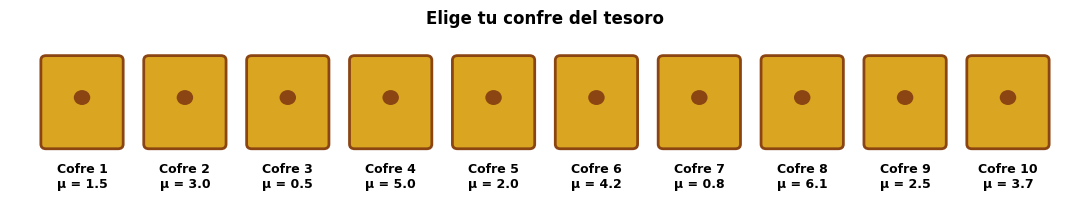

In [84]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches


MEDIAS_CAJAS = [1.5, 3.0, 0.5, 5.0, 2.0, 4.2, 0.8, 6.1, 2.5, 3.7]
K_CAJAS = len(MEDIAS_CAJAS)


fig, ax = plt.subplots(figsize=(11, 2.2))

for i, media in enumerate(MEDIAS_CAJAS):

    cofre = patches.FancyBboxPatch(
        (i - 0.35, 0.5), 0.7, 0.9, boxstyle="round,pad=0.05", ec="#8B4513", fc="#DAA520", lw=2
    )
    ax.add_patch(cofre)


    ax.add_patch(patches.Circle((i, 1.0), 0.08, fc="#8B4513"))

    ax.text(i, 0.15, f"Cofre {i+1}\nμ = {media}", ha="center", va="center", fontsize=9, fontweight="bold")

ax.set_xlim(-0.7, K_CAJAS - 0.3)
ax.set_ylim(-0.1, 1.7)
ax.axis("off")
plt.title("Elige tu confre del tesoro", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

In [85]:
def simular_epsilon_greedy(episodios=1000, epsilon=0.8, alpha=None):

    Q = np.zeros(K_CAJAS)
    N = np.zeros(K_CAJAS)
    historial_recompensas = []

    for t in range(1, episodios + 1):

        if np.random.rand() < epsilon:
            accion = np.random.choice(K_CAJAS)
        else:

            max_q = np.max(Q)
            mejores = [a for a in range(K_CAJAS) if Q[a] == max_q]
            accion = np.random.choice(mejores)


        recompensa = abrir_caja(accion)
        N[accion] += 1


        tasa_aprendizaje = alpha if alpha is not None else (1.0 / N[accion])
        Q[accion] += tasa_aprendizaje * (recompensa - Q[accion])

        historial_recompensas.append(recompensa)

    return Q, N, historial_recompensas

In [86]:
def simular_ucb(episodios=1000, c=0.8):
    Q = np.zeros(K_CAJAS)
    N = np.zeros(K_CAJAS)
    historial_recompensas = []

    for t in range(1, episodios + 1):
        valores_ucb = []
        for a in range(K_CAJAS):
            if N[a] == 0:
                valores_ucb.append(float('inf'))
            else:
                incertidumbre = c * math.sqrt(math.log(t) / N[a])
                valores_ucb.append(Q[a] + incertidumbre)

        max_val = max(valores_ucb)
        mejores = [a for a in range(K_CAJAS) if valores_ucb[a] == max_val]
        accion = np.random.choice(mejores)

        recompensa = abrir_caja(accion)
        N[accion] += 1
        Q[accion] += (1.0 / N[accion]) * (recompensa - Q[accion])

        historial_recompensas.append(recompensa)

    return Q, N, historial_recompensas

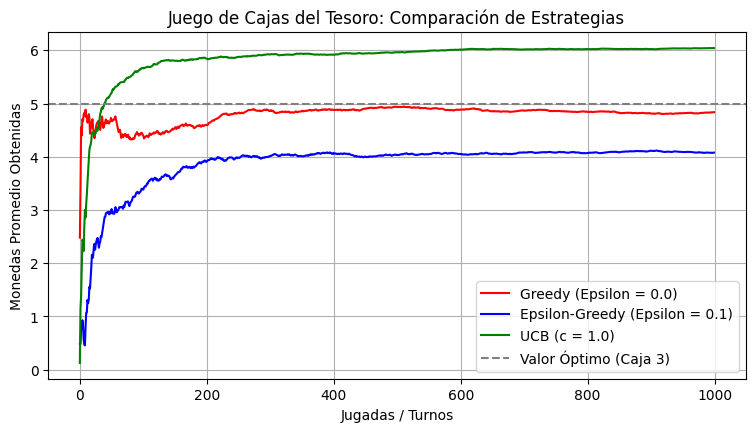

Estimación final de la Tabla Q con UCB: [2.18 1.86 0.13 5.22 1.62 3.97 1.09 6.08 3.41 2.3 ]


In [87]:
EPISODIOS = 1000


Q_greedy, _, r_greedy = simular_epsilon_greedy(EPISODIOS, epsilon=0.4)
Q_eps, _, r_eps = simular_epsilon_greedy(EPISODIOS, epsilon=0.6)
Q_ucb, N_ucb, r_ucb = simular_ucb(EPISODIOS, c=1.0)


prom_greedy = np.cumsum(r_greedy) / (np.arange(EPISODIOS) + 1)
prom_eps = np.cumsum(r_eps) / (np.arange(EPISODIOS) + 1)
prom_ucb = np.cumsum(r_ucb) / (np.arange(EPISODIOS) + 1)


plt.figure(figsize=(9, 4.5))
plt.plot(prom_greedy, label="Greedy (Epsilon = 0.0)", color="red")
plt.plot(prom_eps, label="Epsilon-Greedy (Epsilon = 0.1)", color="blue")
plt.plot(prom_ucb, label="UCB (c = 1.0)", color="green")
plt.axhline(y=5.0, color="gray", linestyle="--", label="Valor Óptimo (Caja 3)")

plt.title("Juego de Cajas del Tesoro: Comparación de Estrategias")
plt.xlabel("Jugadas / Turnos")
plt.ylabel("Monedas Promedio Obtenidas")
plt.grid(True)
plt.legend()
plt.show()
print("Estimación final de la Tabla Q con UCB:", np.round(Q_ucb, 2))

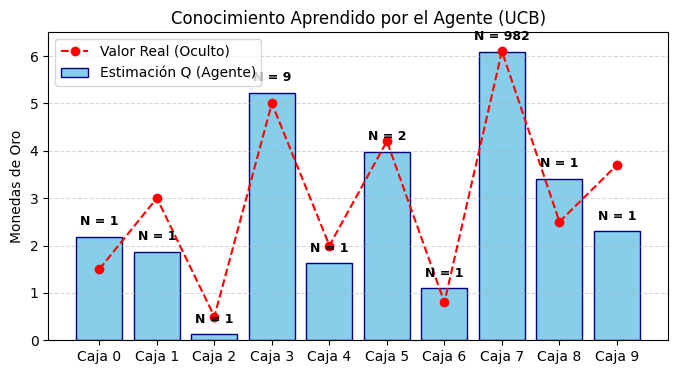

In [88]:
import matplotlib.pyplot as plt

cajas = [f"Caja {i}" for i in range(K_CAJAS)]

plt.figure(figsize=(8, 4))


barras = plt.bar(cajas, Q_ucb, color='skyblue', edgecolor='navy', label="Estimación Q (Agente)")


plt.plot(cajas, MEDIAS_CAJAS, 'ro--', label="Valor Real (Oculto)")


for i in range(K_CAJAS):
    plt.text(i, Q_ucb[i] + 0.25, f"N = {int(N_ucb[i])}", ha='center', fontsize=9, weight='bold')

plt.ylabel("Monedas de Oro")
plt.title("Conocimiento Aprendido por el Agente (UCB)")
plt.ylim(0, 6.5)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()
plt.show()